In [1]:
import json
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, RandomizedSearchCV

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.wrappers.scikit_learn import KerasClassifier

from imblearn.over_sampling import SMOTE

2025-04-29 11:10:03.597901: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 11:10:03.597927: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../Edge-IIoTset_DNN-112.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [5]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [6]:
print(df['Attack_type'].value_counts())

Attack_type
Normal       1399624
DDoS          288112
Injection     102851
Malware        83648
Scanning       70856
MITM             358
Name: count, dtype: int64


In [7]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [8]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [9]:
print(df['Attack_type'].value_counts())

Attack_type
0    1399624
1     288112
3     102851
5      83648
2      70856
4        358
Name: count, dtype: int64


In [10]:
# Apply the Chi-Squared test
chi_selector = SelectKBest(chi2, k='all')  # Set k to the desired number of features
X_kbest = chi_selector.fit_transform(X, y)

In [11]:
# Get the scores for each feature
chi_scores = chi_selector.scores_

# Combine scores with feature names
chi_scores = pd.DataFrame({'feature': X.columns, 'score': chi_scores})

# Sort the features by their scores
chi_scores = chi_scores.sort_values(by='score', ascending=False)

print(chi_scores)

                    feature         score
8               tcp.ack_raw  3.090813e+14
7                   tcp.ack  1.448397e+14
18                  tcp.seq  7.310286e+12
20               udp.stream  9.184477e+11
4   icmp.transmit_timestamp  1.689471e+11
..                      ...           ...
89                  mqtt1_8  1.169939e+00
84                  mqtt1_3  7.799595e-01
85                  mqtt1_4  7.799595e-01
90                  mqtt1_9  7.799595e-01
91                 mqtt1_10  7.799595e-01

[97 rows x 2 columns]


In [12]:
selected_features = chi_scores['feature'].tolist()[:93]  # Select top k features

In [13]:
# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.022, random_state=42)

# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.01388, random_state=42)

In [14]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1876240, 93)
X_val shape: (26409, 93)
X_test shape: (42800, 93)


In [15]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [16]:
# Determine subsample size (e.g., 2% of the training data)
subsample_size = int(0.02 * len(X_train))

# Perform stratified sampling on the training data
X_subsample, _, y_subsample, _ = train_test_split(
    X_train, y_train,
    train_size=subsample_size,
    stratify=y_train,
    random_state=42
)

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply SMOTE to the subsampled training data
X_resampled, y_resampled = smote.fit_resample(X_subsample, y_subsample)

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


In [17]:
print("X_train_subsample shape:", X_resampled.shape)

X_train_subsample shape: (161952, 93)


In [18]:
param_grid = {
    "filters":        [16, 32, 64],
    "kernel_size":    [3, 5],
    "dropout_rate":   [0.3, 0.5],
    "learning_rate":  [1e-3, 5e-4],
    "optimizer":      ["adam"],
    "l2_reg":         [0.0, 1e-4],
    "batch_size":     [16, 32],
    "epochs":         [5, 10],
}

In [19]:
# Initialize the 1D CNN classifier
def model_1d_cnn(
        input_shape,
        num_classes=6,
        filters=64,
        kernel_size=3,
        pool_size=2,
        dropout_rate=0.5,
        dense_units=100,
        learning_rate=1e-3,
        optimizer="adam",
        l2_reg=0.0,
):
    _model = Sequential([
        Conv1D(filters=filters,
               kernel_size=kernel_size,
               activation="relu",
               kernel_regularizer=l2(l2_reg),
               input_shape=input_shape),
        MaxPooling1D(pool_size=pool_size),
        Dropout(dropout_rate),
        Flatten(),
        Dense(dense_units, activation="relu"),
    ])

    if num_classes == 2:
        _model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        _model.add(Dense(num_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    # choose optimiser
    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == "rmsprop":
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("Unknown optimiser.")

    _model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return _model

In [20]:
keras_classifier = KerasClassifier(
    build_fn=model_1d_cnn,
    input_shape=(X_train.shape[1], 1),
    num_classes=6,
    verbose=0
)

early_stop = EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search_cv = GridSearchCV(
        estimator=keras_classifier,
        param_grid=param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=12,
        refit=True,
        verbose=2,
        return_train_score=True
)

# search_cv = RandomizedSearchCV(estimator=keras_classifier,
#                                    param_distributions=param_grid,
#                                    n_iter=100,  # Number of parameter settings sampled
#                                    scoring='accuracy',
#                                    cv=cv,
#                                    n_jobs=12,
#                                    refit=True,
#                                    verbose=2,
#                                    return_train_score=True,
#                                    random_state=42)

/tmp/ipykernel_7086/2290727179.py:1: DeprecationWarning: KerasClassifier is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead.
  keras_classifier = KerasClassifier(


In [21]:
# Train the model
search_cv.fit(X_resampled, y_resampled,
                validation_data=(X_val, y_val),
                callbacks=[early_stop])

best_model = search_cv.best_estimator_

Fitting 5 folds for each of 192 candidates, totalling 960 fits


2025-04-29 11:10:25.860726: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 11:10:25.860765: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-04-29 11:10:25.861442: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 11:10:25.861477: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-04-29 11:10:25.874270: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or dire

[CV] END batch_size=16, dropout_rate=0.3, epochs=5, filters=16, kernel_size=3, l2_reg=0.0, learning_rate=0.001, optimizer=adam; total time= 3.3min
[CV] END batch_size=16, dropout_rate=0.3, epochs=5, filters=16, kernel_size=5, l2_reg=0.0, learning_rate=0.001, optimizer=adam; total time= 3.3min
[CV] END batch_size=16, dropout_rate=0.3, epochs=5, filters=16, kernel_size=5, l2_reg=0.0001, learning_rate=0.001, optimizer=adam; total time= 3.4min
[CV] END batch_size=16, dropout_rate=0.3, epochs=5, filters=32, kernel_size=3, l2_reg=0.0, learning_rate=0.001, optimizer=adam; total time= 4.9min
[CV] END batch_size=16, dropout_rate=0.3, epochs=5, filters=32, kernel_size=3, l2_reg=0.0001, learning_rate=0.0005, optimizer=adam; total time= 5.2min
[CV] END batch_size=16, dropout_rate=0.3, epochs=5, filters=32, kernel_size=5, l2_reg=0.0, learning_rate=0.0005, optimizer=adam; total time= 5.1min
[CV] END batch_size=16, dropout_rate=0.3, epochs=5, filters=32, kernel_size=5, l2_reg=0.0001, learning_rate=0.

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
2025-04-29 17:35:06.456876: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 17:35:06.456950: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-04-29 17:35:10.195792: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-04-29 17:35:10.199513: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynami

[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=32, kernel_size=5, l2_reg=0.0, learning_rate=0.0005, optimizer=adam; total time= 3.2min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=32, kernel_size=5, l2_reg=0.0001, learning_rate=0.0005, optimizer=adam; total time= 4.0min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=3, l2_reg=0.0001, learning_rate=0.001, optimizer=adam; total time= 6.3min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=5, l2_reg=0.0, learning_rate=0.001, optimizer=adam; total time= 6.1min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=5, l2_reg=0.0001, learning_rate=0.001, optimizer=adam; total time= 5.9min
[CV] END batch_size=32, dropout_rate=0.3, epochs=10, filters=16, kernel_size=3, l2_reg=0.0, learning_rate=0.0005, optimizer=adam; total time= 4.5min
Restoring model weights from the end of the best epoch: 2.
Epoch 00008: early stopping
[CV] END batch_siz

2025-04-29 17:51:42.893817: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 17:51:42.893911: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-04-29 17:51:47.331974: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-04-29 17:51:47.335748: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 17:51:47.336362: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.s

... (9 outputs left out)

2025-04-29 19:52:03.281024: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 19:52:03.283216: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-04-29 19:52:07.932991: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-04-29 19:52:07.937699: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 19:52:07.938178: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.s

[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=32, kernel_size=5, l2_reg=0.0001, learning_rate=0.0005, optimizer=adam; total time= 3.7min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=3, l2_reg=0.0, learning_rate=0.0005, optimizer=adam; total time= 6.2min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=5, l2_reg=0.0, learning_rate=0.001, optimizer=adam; total time= 6.2min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=5, l2_reg=0.0001, learning_rate=0.001, optimizer=adam; total time= 6.1min
Restoring model weights from the end of the best epoch: 1.
Epoch 00007: early stopping
[CV] END batch_size=32, dropout_rate=0.3, epochs=10, filters=16, kernel_size=3, l2_reg=0.0, learning_rate=0.001, optimizer=adam; total time= 3.5min
Restoring model weights from the end of the best epoch: 1.
Epoch 00007: early stopping
[CV] END batch_size=32, dropout_rate=0.3, epochs=10, filters=16, kernel_size=3, l2

2025-04-29 20:06:45.635754: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 20:06:45.636393: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-04-29 20:06:50.434356: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-04-29 20:06:50.439122: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-04-29 20:06:50.440626: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.s

[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=32, kernel_size=3, l2_reg=0.0, learning_rate=0.0005, optimizer=adam; total time= 3.3min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=32, kernel_size=3, l2_reg=0.0001, learning_rate=0.0005, optimizer=adam; total time= 3.3min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=32, kernel_size=5, l2_reg=0.0001, learning_rate=0.001, optimizer=adam; total time= 3.3min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=3, l2_reg=0.0, learning_rate=0.001, optimizer=adam; total time= 5.8min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=3, l2_reg=0.0001, learning_rate=0.001, optimizer=adam; total time= 6.3min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=5, l2_reg=0.0, learning_rate=0.0005, optimizer=adam; total time= 6.1min
[CV] END batch_size=32, dropout_rate=0.3, epochs=5, filters=64, kernel_size=5, l2_reg=0.0001, learning_rat

In [22]:
print('Best Hyperparameters:')
print(search_cv.best_params_)

Best Hyperparameters:
{'batch_size': 16, 'dropout_rate': 0.3, 'epochs': 10, 'filters': 64, 'kernel_size': 5, 'l2_reg': 0.0001, 'learning_rate': 0.0005, 'optimizer': 'adam'}


In [23]:
y_pred = best_model.predict(np.expand_dims(X_test, axis=2))

In [25]:
y_pred

array([0, 1, 0, ..., 0, 2, 0])

In [26]:
y_pred_classes = y_pred

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     30949
        DDoS       0.98      0.94      0.96      6185
    Scanning       0.79      0.94      0.86      1542
   Injection       0.70      0.87      0.78      2281
        MITM       1.00      1.00      1.00        10
     Malware       0.88      0.61      0.72      1833

    accuracy                           0.97     42800
   macro avg       0.89      0.89      0.89     42800
weighted avg       0.97      0.97      0.97     42800



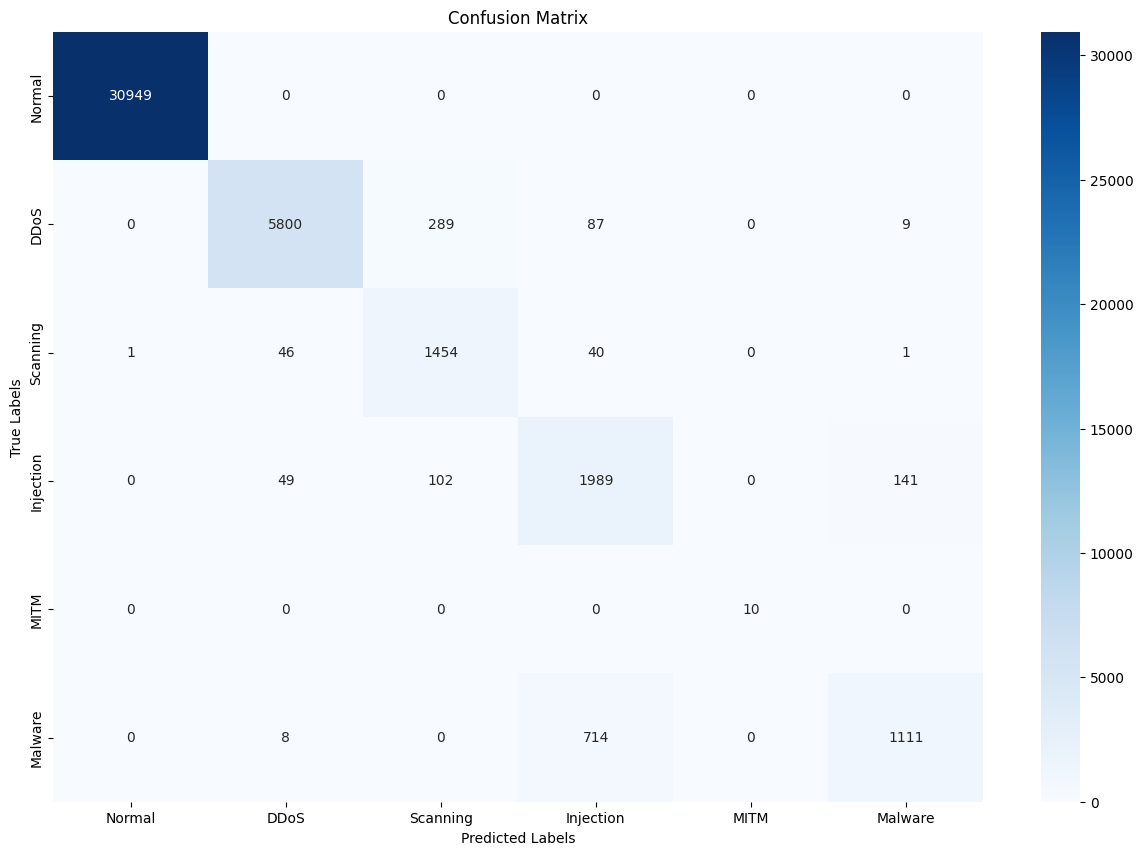

In [27]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
# plt.savefig('con_mat.jpg')

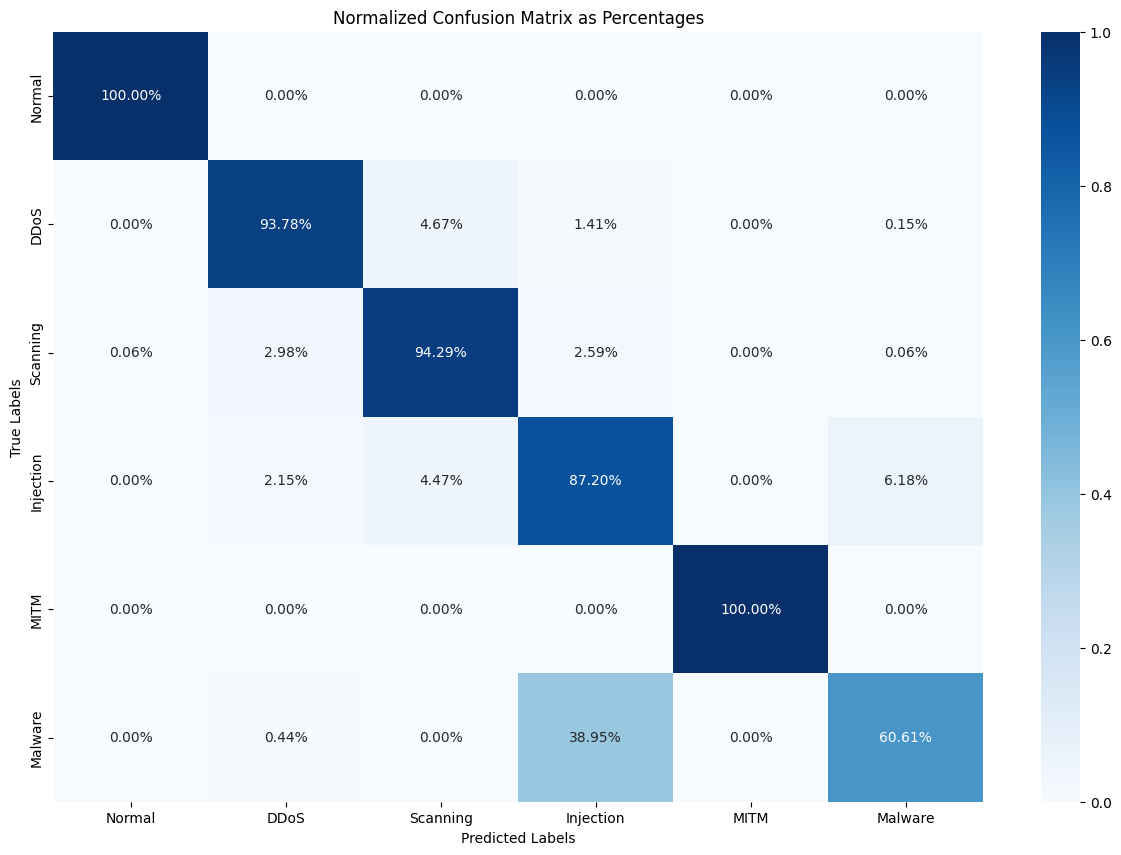

In [28]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')

In [29]:
best_model.model.save("1d_cnn_model_6.h5")

In [30]:
with open('HP_1d_cnn_6.json', 'w') as f:
    json.dump(search_cv.best_params_, f)